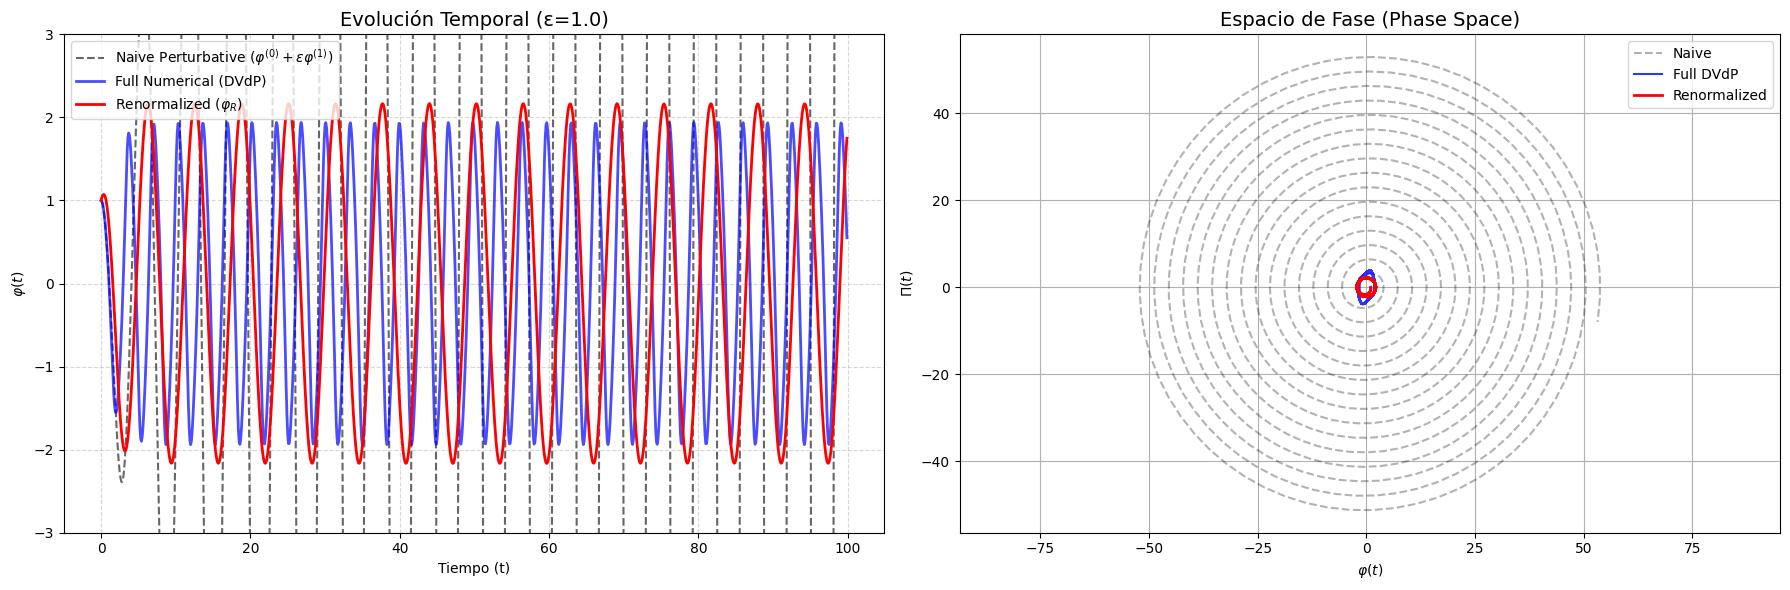

In [ ]:
# @title Algoritmo de Renormalización para DVdP

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y PARÁMETROS (El "Setup")
# ---------------------------------------------------------
omega = 1.0       # Frecuencia angular natural
epsilon = 1.0     # Parámetro de deformación (pequeño para que funque la teoría)
A0_init = 1.0     # Amplitud inicial
t_start = 0.0
t_end = 100.0     # Tiempo de simulación (largo para ver el ciclo límite)
dt = 0.1
t_eval = np.arange(t_start, t_end, dt)

# ---------------------------------------------------------
# 2. DEFINICIÓN DE SISTEMAS
# ---------------------------------------------------------

# A) Solución "Full" (La exacta)

def vdp_full_system(t, y):
    phi, Pi = y
    # Ecuación: dPi/dt = -w^2 phi + eps*(1 - phi^2)*Pi
    dphi = Pi
    dPi = -omega**2 * phi- epsilon*phi**3 + epsilon * (1 - phi**2) * Pi
    return [dphi, dPi]

# B) Solución de Fondo (Background) - Ec. 18 del paper
def phi_0(t, A):
    return A * np.cos(omega * t)

def Pi_0(t, A):
    return -omega * A * np.sin(omega * t)

# C) Sistema Perturbativo (Primer Orden) - Ec. 19 del paper
# Ojo: Aquí calculamos phi_1 (la corrección) asumiendo A constante temporalmente para este paso
def perturbative_system(t, y, A_fixed):
    phi1, Pi1 = y

    # Background solutions at time t with FIXED Amplitude
    p0 = phi_0(t, A_fixed)
    pi0 = Pi_0(t, A_fixed)

    # Ec 19a y 19b:
    # dPi1/dt = -w^2 phi1 + Pi0 * (1 - p0^2)  <-- Término fuente secular
    dphi1 = Pi1
    dPi1 = -omega**2 * phi1- p0**3 + pi0 * (1 - p0**2)
    return [dphi1, dPi1]

# ---------------------------------------------------------
# 3. EL NÚCLEO DE LA RENORMALIZACIÓN
# ---------------------------------------------------------

# Creamos una grilla de Amplitudes para caracterizar cómo crece el error en cada nivel
A_grid = np.linspace(0.1, 4.0, 20)
beta_vals = []

# Para cada amplitud A, resolvemos la perturbación y proyectamos el error
for A_val in A_grid:
    # Resolvemos la EDO perturbativa por un periodo corto (suficiente para captar la tendencia secular)
    # No necesitamos integrar hasta t=100, solo ver la "velocidad" de divergencia inicial.
    T_period = 2 * np.pi / omega
    t_short = np.linspace(0, 4*T_period, 100) # 4 periodos

    sol_pert = solve_ivp(perturbative_system, [0, 4*T_period], [0, 0],
                         args=(A_val,), t_eval=t_short, method='RK45')

    phi1_num = sol_pert.y[0]

    # --- PROYECCIÓN (Cálculo de Beta) ---
    # Teoría: phi_total ~= phi0(A) + eps * phi1
    # Renorm: phi_renorm ~= phi0(A(t))
    # La diferencia secular es phi1 ~ t * (d_phi0/dA) * Beta
    # Entonces Beta es la pendiente que mejor ajusta phi1 vs t * d_phi0/dA

    # Derivada del background respecto a A: cos(wt)
    d_phi0_dA = np.cos(omega * t_short)

    # El término secular crece como t. Queremos encontrar Beta tal que:
    # phi1(t) ~= Beta * t * d_phi0_dA
    # Usamos mínimos cuadrados para hallar Beta para este A específico.

    predictor = t_short * d_phi0_dA  # El "x" de la regresión
    response = phi1_num              # El "y" de la regresión

    # Regresión lineal simple pasando por el origen (y = m*x)
    # beta = sum(x*y) / sum(x^2)
    beta = np.sum(predictor * response) / np.sum(predictor**2)
    beta_vals.append(beta)

# Creamos una función interpolada para Beta(A)
# Esto es la Ec. 22 del paper pero numérica: dA/dt = eps * Beta(A)
beta_function = interp1d(A_grid, beta_vals, kind='cubic', fill_value="extrapolate")

# ---------------------------------------------------------
# 4. RESOLVIENDO LOS TRES MÉTODOS
# ---------------------------------------------------------

# --- A. Full Solution ---
sol_full = solve_ivp(vdp_full_system, [t_start, t_end], [A0_init, 0], t_eval=t_eval)
y_full = sol_full.y[0]
pi_full = sol_full.y[1]

# --- B. Naive Perturbative Solution ---
# phi_naive = phi0 + eps * phi1 (con A fijo inicial)
sol_naive_pert = solve_ivp(perturbative_system, [t_start, t_end], [0, 0],
                           args=(A0_init,), t_eval=t_eval)
y_naive = phi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[0]
pi_naive = Pi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[1]

# --- C. Renormalized Solution ---
# Resolvemos la ecuación de flujo: dA_R/dt = eps * beta(A_R)
def amplitude_flow(t, A):
    return epsilon * beta_function(A)

sol_renorm_amp = solve_ivp(amplitude_flow, [t_start, t_end], [A0_init], t_eval=t_eval)
A_R_t = sol_renorm_amp.y[0]

# Reconstruimos la solución: phi_R(t) = A_R(t) * cos(wt)
y_renorm = A_R_t * np.cos(omega * t_eval)
pi_renorm = -omega * A_R_t * np.sin(omega * t_eval) # Aproximación de momento

# ---------------------------------------------------------
# 5. GRAFICANDO RESULTADOS
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Gráfica 1: Serie de Tiempo
ax1.set_title(f"Evolución Temporal (ε={epsilon})", fontsize=14)
ax1.plot(t_eval, y_naive, 'k--', alpha=0.6, label=r'Naive Perturbative ($\varphi^{(0)} + \epsilon\varphi^{(1)}$)')
ax1.plot(t_eval, y_full, 'b-', linewidth=2, alpha=0.7, label='Full Numerical (DVdP)')
ax1.plot(t_eval, y_renorm, 'r-', linewidth=2, label=r'Renormalized ($\varphi_R$)')
ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel(r'$\varphi(t)$')
ax1.legend(loc='upper left')
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
ax1.set_ylim(-3, 3)

# Gráfica 2: Espacio de Fase
ax2.set_title("Espacio de Fase (Phase Space)", fontsize=14)
ax2.plot(y_naive, pi_naive, 'k--', alpha=0.3, label='Naive')
ax2.plot(y_full, pi_full, 'b-', alpha=0.8, label='Full DVdP')
ax2.plot(y_renorm, pi_renorm, 'r-', linewidth=2, label='Renormalized')
ax2.set_xlabel(r'$\varphi(t)$')
ax2.set_ylabel(r'$\Pi(t)$')
ax2.legend()
ax2.grid(True)
ax2.axis('equal')

plt.tight_layout()
plt.show()

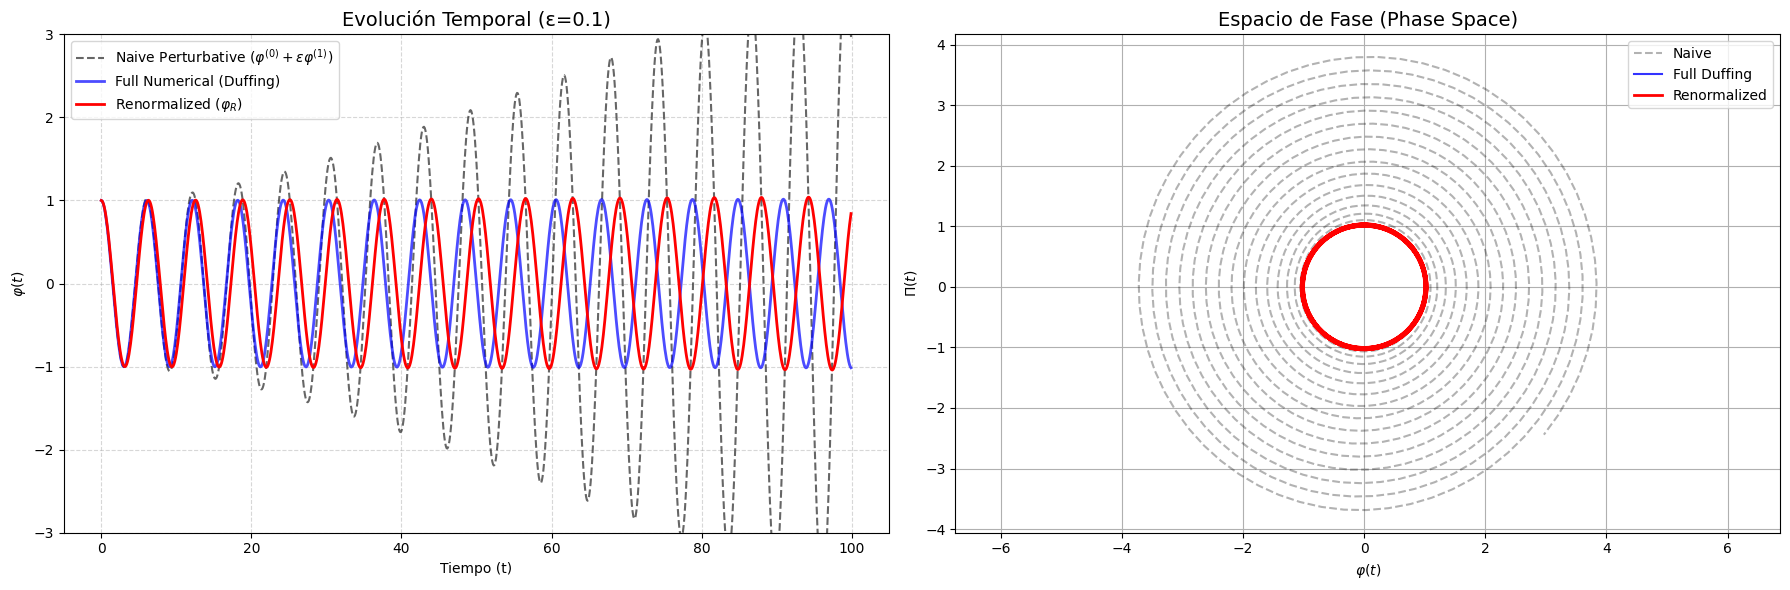

In [ ]:
# @title Algoritmo de Renormalización para Duffing

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y PARÁMETROS (El "Setup")
# ---------------------------------------------------------
omega = 1.0       # Frecuencia angular natural
epsilon = 0.1     # Parámetro de deformación (pequeño para que funque la teoría)
A0_init = 1.0     # Amplitud inicial
t_start = 0.0
t_end = 100.0     # Tiempo de simulación (largo para ver el ciclo límite)
dt = 0.1
t_eval = np.arange(t_start, t_end, dt)

# ---------------------------------------------------------
# 2. DEFINICIÓN DE SISTEMAS
# ---------------------------------------------------------

# A) Solución "Full" (La exacta)

def vdp_full_system(t, y):
    phi, Pi = y
    # Ecuación: dPi/dt = -w^2 phi + eps*(1 - phi^2)*Pi
    dphi = Pi
    dPi = -omega**2 * phi- epsilon*phi**3
    return [dphi, dPi]

# B) Solución de Fondo (Background) - Ec. 18 del paper
def phi_0(t, A):
    return A * np.cos(omega * t)

def Pi_0(t, A):
    return -omega * A * np.sin(omega * t)

# C) Sistema Perturbativo (Primer Orden) - Ec. 19 del paper
# Ojo: Aquí calculamos phi_1 (la corrección) asumiendo A constante temporalmente para este paso
def perturbative_system(t, y, A_fixed):
    phi1, Pi1 = y

    # Background solutions at time t with FIXED Amplitude
    p0 = phi_0(t, A_fixed)
    pi0 = Pi_0(t, A_fixed)

    # Ec 19a y 19b:
    # dPi1/dt = -w^2 phi1 + Pi0 * (1 - p0^2)  <-- Término fuente secular
    dphi1 = Pi1
    dPi1 = -omega**2 * phi1- p0**3
    return [dphi1, dPi1]

# ---------------------------------------------------------
# 3. EL NÚCLEO DE LA RENORMALIZACIÓN
# ---------------------------------------------------------

# Creamos una grilla de Amplitudes para caracterizar cómo crece el error en cada nivel
A_grid = np.linspace(0.1, 4.0, 20)
beta_vals = []

# Para cada amplitud A, resolvemos la perturbación y proyectamos el error
for A_val in A_grid:
    # Resolvemos la EDO perturbativa por un periodo corto (suficiente para captar la tendencia secular)
    # No necesitamos integrar hasta t=100, solo ver la "velocidad" de divergencia inicial.
    T_period = 2 * np.pi / omega
    t_short = np.linspace(0, 10*T_period, 100) # 4 periodos

    sol_pert = solve_ivp(perturbative_system, [0, 10*T_period], [0, 0],
                         args=(A_val,), t_eval=t_short, method='RK45')

    phi1_num = sol_pert.y[0]

    # --- PROYECCIÓN (Cálculo de Beta) ---
    # Teoría: phi_total ~= phi0(A) + eps * phi1
    # Renorm: phi_renorm ~= phi0(A(t))
    # La diferencia secular es phi1 ~ t * (d_phi0/dA) * Beta
    # Entonces Beta es la pendiente que mejor ajusta phi1 vs t * d_phi0/dA

    # Derivada del background respecto a A: cos(wt)
    d_phi0_dA = np.cos(omega * t_short)

    # El término secular crece como t. Queremos encontrar Beta tal que:
    # phi1(t) ~= Beta * t * d_phi0_dA
    # Usamos mínimos cuadrados para hallar Beta para este A específico.

    predictor = t_short * d_phi0_dA  # El "x" de la regresión
    response = phi1_num              # El "y" de la regresión

    # Regresión lineal simple pasando por el origen (y = m*x)
    # beta = sum(x*y) / sum(x^2)
    beta = np.sum(predictor * response) / np.sum(predictor**2)
    beta_vals.append(beta)

# Creamos una función interpolada para Beta(A)
# Esto es la Ec. 22 del paper pero numérica: dA/dt = eps * Beta(A)
beta_function = interp1d(A_grid, beta_vals, kind='cubic', fill_value="extrapolate")

# ---------------------------------------------------------
# 4. RESOLVIENDO LOS TRES MÉTODOS
# ---------------------------------------------------------

# --- A. Full Solution ---
sol_full = solve_ivp(vdp_full_system, [t_start, t_end], [A0_init, 0], t_eval=t_eval)
y_full = sol_full.y[0]
pi_full = sol_full.y[1]

# --- B. Naive Perturbative Solution ---
# phi_naive = phi0 + eps * phi1 (con A fijo inicial)
sol_naive_pert = solve_ivp(perturbative_system, [t_start, t_end], [0, 0],
                           args=(A0_init,), t_eval=t_eval)
y_naive = phi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[0]
pi_naive = Pi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[1]

# --- C. Renormalized Solution ---
# Resolvemos la ecuación de flujo: dA_R/dt = eps * beta(A_R)
def amplitude_flow(t, A):
    return epsilon * beta_function(A)

sol_renorm_amp = solve_ivp(amplitude_flow, [t_start, t_end], [A0_init], t_eval=t_eval)
A_R_t = sol_renorm_amp.y[0]

# Reconstruimos la solución: phi_R(t) = A_R(t) * cos(wt)
y_renorm = A_R_t * np.cos(omega * t_eval)
pi_renorm = -omega * A_R_t * np.sin(omega * t_eval) # Aproximación de momento

# ---------------------------------------------------------
# 5. GRAFICANDO RESULTADOS
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Gráfica 1: Serie de Tiempo
ax1.set_title(f"Evolución Temporal (ε={epsilon})", fontsize=14)
ax1.plot(t_eval, y_naive, 'k--', alpha=0.6, label=r'Naive Perturbative ($\varphi^{(0)} + \epsilon\varphi^{(1)}$)')
ax1.plot(t_eval, y_full, 'b-', linewidth=2, alpha=0.7, label='Full Numerical (Duffing)')
ax1.plot(t_eval, y_renorm, 'r-', linewidth=2, label=r'Renormalized ($\varphi_R$)')
ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel(r'$\varphi(t)$')
ax1.legend(loc='upper left')
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
ax1.set_ylim(-3, 3)

# Gráfica 2: Espacio de Fase
ax2.set_title("Espacio de Fase (Phase Space)", fontsize=14)
ax2.plot(y_naive, pi_naive, 'k--', alpha=0.3, label='Naive')
ax2.plot(y_full, pi_full, 'b-', alpha=0.8, label='Full Duffing')
ax2.plot(y_renorm, pi_renorm, 'r-', linewidth=2, label='Renormalized')
ax2.set_xlabel(r'$\varphi(t)$')
ax2.set_ylabel(r'$\Pi(t)$')
ax2.legend()
ax2.grid(True)
ax2.axis('equal')

plt.tight_layout()
plt.show()

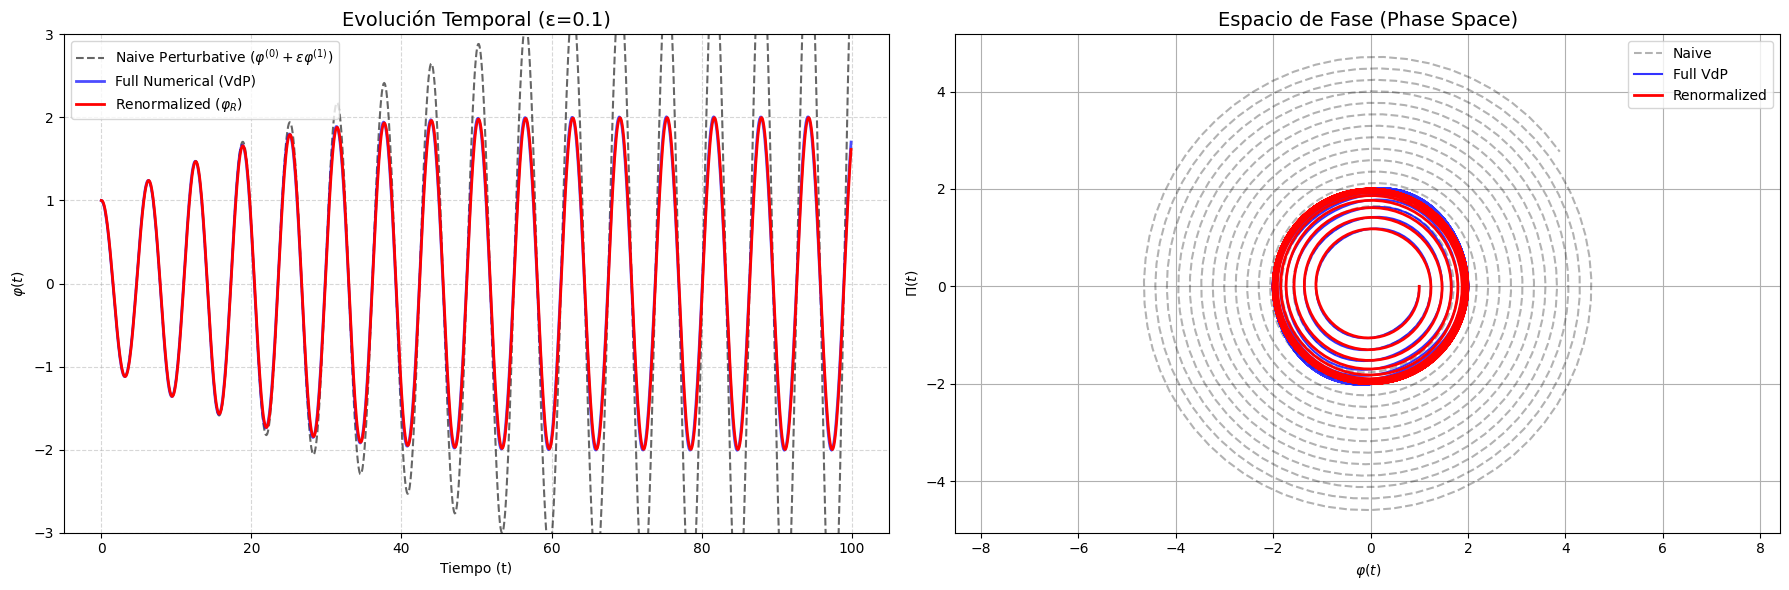

In [ ]:
# @title Algoritmo de Renormalización para VdP

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y PARÁMETROS (El "Setup")
# ---------------------------------------------------------
omega = 1.0       # Frecuencia angular natural
epsilon = 0.1     # Parámetro de deformación (pequeño para que funque la teoría)
A0_init = 1.0     # Amplitud inicial
t_start = 0.0
t_end = 100.0     # Tiempo de simulación (largo para ver el ciclo límite)
dt = 0.1
t_eval = np.arange(t_start, t_end, dt)

# ---------------------------------------------------------
# 2. DEFINICIÓN DE SISTEMAS
# ---------------------------------------------------------

# A) Solución "Full" (La exacta)

def vdp_full_system(t, y):
    phi, Pi = y
    # Ecuación: dPi/dt = -w^2 phi + eps*(1 - phi^2)*Pi
    dphi = Pi
    dPi = -omega**2 * phi + epsilon * (1 - phi**2) * Pi
    return [dphi, dPi]

# B) Solución de Fondo (Background) - Ec. 18 del paper
def phi_0(t, A):
    return A * np.cos(omega * t)

def Pi_0(t, A):
    return -omega * A * np.sin(omega * t)

# C) Sistema Perturbativo (Primer Orden) - Ec. 19 del paper
# Ojo: Aquí calculamos phi_1 (la corrección) asumiendo A constante temporalmente para este paso
def perturbative_system(t, y, A_fixed):
    phi1, Pi1 = y

    # Background solutions at time t with FIXED Amplitude
    p0 = phi_0(t, A_fixed)
    pi0 = Pi_0(t, A_fixed)

    # Ec 19a y 19b:
    # dPi1/dt = -w^2 phi1 + Pi0 * (1 - p0^2)  <-- Término fuente secular
    dphi1 = Pi1
    dPi1 = -omega**2 * phi1 +pi0 * (1 - p0**2)
    return [dphi1, dPi1]

# ---------------------------------------------------------
# 3. EL NÚCLEO DE LA RENORMALIZACIÓN
# ---------------------------------------------------------

# Creamos una grilla de Amplitudes para caracterizar cómo crece el error en cada nivel
A_grid = np.linspace(0.1, 4.0, 20)
beta_vals = []

# Para cada amplitud A, resolvemos la perturbación y proyectamos el error
for A_val in A_grid:
    # Resolvemos la EDO perturbativa por un periodo corto (suficiente para captar la tendencia secular)
    # No necesitamos integrar hasta t=100, solo ver la "velocidad" de divergencia inicial.
    T_period = 2 * np.pi / omega
    t_short = np.linspace(0, 4*T_period, 100) # 4 periodos

    sol_pert = solve_ivp(perturbative_system, [0, 4*T_period], [0, 0],
                         args=(A_val,), t_eval=t_short, method='RK45')

    phi1_num = sol_pert.y[0]

    # --- PROYECCIÓN (Cálculo de Beta) ---
    # Teoría: phi_total ~= phi0(A) + eps * phi1
    # Renorm: phi_renorm ~= phi0(A(t))
    # La diferencia secular es phi1 ~ t * (d_phi0/dA) * Beta
    # Entonces Beta es la pendiente que mejor ajusta phi1 vs t * d_phi0/dA

    # Derivada del background respecto a A: cos(wt)
    d_phi0_dA = np.cos(omega * t_short)

    # El término secular crece como t. Queremos encontrar Beta tal que:
    # phi1(t) ~= Beta * t * d_phi0_dA
    # Usamos mínimos cuadrados para hallar Beta para este A específico.

    predictor = t_short * d_phi0_dA  # El "x" de la regresión
    response = phi1_num              # El "y" de la regresión

    # Regresión lineal simple pasando por el origen (y = m*x)
    # beta = sum(x*y) / sum(x^2)
    beta = np.sum(predictor * response) / np.sum(predictor**2)
    beta_vals.append(beta)

# Creamos una función interpolada para Beta(A)
# Esto es la Ec. 22 del paper pero numérica: dA/dt = eps * Beta(A)
beta_function = interp1d(A_grid, beta_vals, kind='cubic', fill_value="extrapolate")

# ---------------------------------------------------------
# 4. RESOLVIENDO LOS TRES MÉTODOS
# ---------------------------------------------------------

# --- A. Full Solution ---
sol_full = solve_ivp(vdp_full_system, [t_start, t_end], [A0_init, 0], t_eval=t_eval)
y_full = sol_full.y[0]
pi_full = sol_full.y[1]

# --- B. Naive Perturbative Solution ---
# phi_naive = phi0 + eps * phi1 (con A fijo inicial)
sol_naive_pert = solve_ivp(perturbative_system, [t_start, t_end], [0, 0],
                           args=(A0_init,), t_eval=t_eval)
y_naive = phi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[0]
pi_naive = Pi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[1]

# --- C. Renormalized Solution ---
# Resolvemos la ecuación de flujo: dA_R/dt = eps * beta(A_R)
def amplitude_flow(t, A):
    return epsilon * beta_function(A)

sol_renorm_amp = solve_ivp(amplitude_flow, [t_start, t_end], [A0_init], t_eval=t_eval)
A_R_t = sol_renorm_amp.y[0]

# Reconstruimos la solución: phi_R(t) = A_R(t) * cos(wt)
y_renorm = A_R_t * np.cos(omega * t_eval)
pi_renorm = -omega * A_R_t * np.sin(omega * t_eval) # Aproximación de momento

# ---------------------------------------------------------
# 5. GRAFICANDO RESULTADOS
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Gráfica 1: Serie de Tiempo
ax1.set_title(f"Evolución Temporal (ε={epsilon})", fontsize=14)
ax1.plot(t_eval, y_naive, 'k--', alpha=0.6, label=r'Naive Perturbative ($\varphi^{(0)} + \epsilon\varphi^{(1)}$)')
ax1.plot(t_eval, y_full, 'b-', linewidth=2, alpha=0.7, label='Full Numerical (VdP)')
ax1.plot(t_eval, y_renorm, 'r-', linewidth=2, label=r'Renormalized ($\varphi_R$)')
ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel(r'$\varphi(t)$')
ax1.legend(loc='upper left')
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
ax1.set_ylim(-3, 3)

# Gráfica 2: Espacio de Fase
ax2.set_title("Espacio de Fase (Phase Space)", fontsize=14)
ax2.plot(y_naive, pi_naive, 'k--', alpha=0.3, label='Naive')
ax2.plot(y_full, pi_full, 'b-', alpha=0.8, label='Full VdP')
ax2.plot(y_renorm, pi_renorm, 'r-', linewidth=2, label='Renormalized')
ax2.set_xlabel(r'$\varphi(t)$')
ax2.set_ylabel(r'$\Pi(t)$')
ax2.legend()
ax2.grid(True)
ax2.axis('equal')

plt.tight_layout()
plt.show()

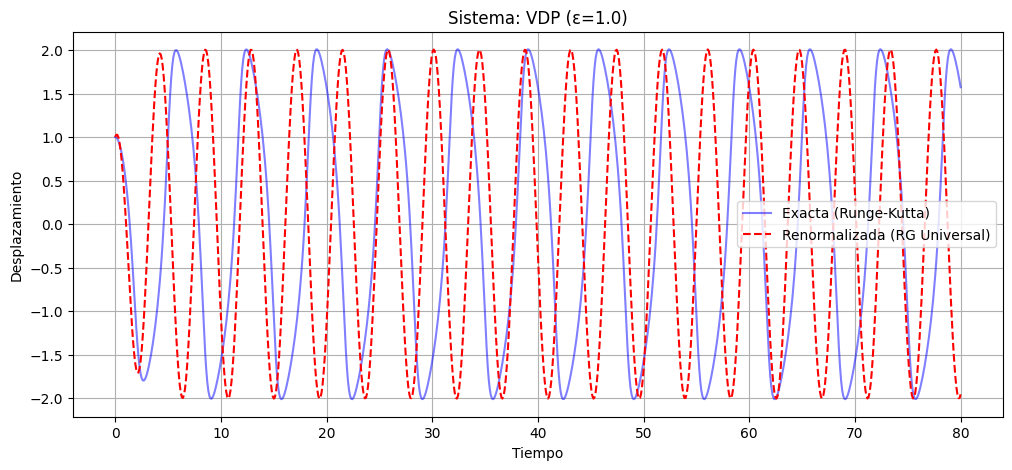

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# ---------------------------------------------------------
# 1. CONFIGURACIÓN UNIVERSAL
# ---------------------------------------------------------
omega_0 = 1.0
epsilon = 1.0
A0_init = 1.0
t_end = 80.0
t_eval = np.linspace(0, t_end, 800)

# Elige tu veneno: 'vdp' (Van der Pol) o 'duffing'
mode = 'vdp'

def system_dynamics(phi, pi, eps):
    if mode == 'vdp':
        return -omega_0**2 * phi + eps * (1 - phi**2) * pi
    elif mode == 'duffing':
        return -omega_0**2 * phi - eps * phi**3
    return 0

# ---------------------------------------------------------
# 2. NÚCLEO DE RENORMALIZACIÓN (Detección de Betas)
# ---------------------------------------------------------
A_grid = np.linspace(0.05, 4.0, 25)
beta_A_list = []
beta_theta_list = []

T_period = 2 * np.pi / omega_0
t_short = np.linspace(0, 2 * T_period, 100)

for A in A_grid:
    # Definimos la perturbación local para este A
    def pert_eq(t, y):
        phi1, pi1 = y
        phi0 = A * np.cos(omega_0 * t)
        pi0 = -omega_0 * A * np.sin(omega_0 * t)

        # El término fuente es la dinámica total evaluada en la solución de fondo
        source = system_dynamics(phi0, pi0, 1.0) # eps=1 aquí para extraer el coeficiente puro
        # Restamos la parte armónica simple para aislar la perturbación
        dphi1 = pi1
        dpi1 = -omega_0**2 * phi1 + source
        return [dphi1, dpi1]

    sol = solve_ivp(pert_eq, [0, 2*T_period], [0, 0], t_eval=t_short)
    phi1_num = sol.y[0]

    # Proyección Dual (Amplitud y Fase)
    # phi1 ~ t * [ beta_A * cos(wt) - A * beta_theta * sin(wt) ]
    X1 = t_short * np.cos(omega_0 * t_short)            # Dirección de Amplitud
    X2 = t_short * (-A * np.sin(omega_0 * t_short))    # Dirección de Fase

    matrix = np.column_stack((X1, X2))
    # Resolvemos por mínimos cuadrados: [beta_A, beta_theta]
    betas, _, _, _ = np.linalg.lstsq(matrix, phi1_num, rcond=None)

    beta_A_list.append(betas[0])
    beta_theta_list.append(betas[1])

# Interpoladores para el flujo de RG
get_beta_A = interp1d(A_grid, beta_A_list, kind='cubic', fill_value="extrapolate")
get_beta_theta = interp1d(A_grid, beta_theta_list, kind='cubic', fill_value="extrapolate")

# ---------------------------------------------------------
# 3. RESOLUCIÓN DE LAS ECUACIONES DE FLUJO (RG)
# ---------------------------------------------------------
def rg_flow(t, y):
    A, theta = y
    # Ecuaciones de la Renormalización:
    dA_dt = epsilon * get_beta_A(A)
    dtheta_dt = epsilon * get_beta_theta(A)
    return [dA_dt, dtheta_dt]

sol_rg = solve_ivp(rg_flow, [0, t_end], [A0_init, 0], t_eval=t_eval)
A_t = sol_rg.y[0]
theta_t = sol_rg.y[1]

# Reconstrucción: phi(t) = A(t) * cos(w*t + theta(t))
y_renorm = A_t * np.cos(omega_0 * t_eval + theta_t)

# ---------------------------------------------------------
# 4. COMPARACIÓN CON SOLUCIÓN NUMÉRICA "REAL"
# ---------------------------------------------------------
def real_system(t, y):
    phi, pi = y
    return [pi, system_dynamics(phi, pi, epsilon)]

sol_real = solve_ivp(real_system, [0, t_end], [A0_init, 0], t_eval=t_eval)
y_real = sol_real.y[0]

# ---------------------------------------------------------
# 5. VISUALIZACIÓN
# ---------------------------------------------------------
plt.figure(figsize=(12, 5))
plt.plot(t_eval, y_real, 'b', alpha=0.5, label='Exacta (Runge-Kutta)')
plt.plot(t_eval, y_renorm, 'r--', label='Renormalizada (RG Universal)')
plt.title(f"Sistema: {mode.upper()} (ε={epsilon})")
plt.xlabel("Tiempo")
plt.ylabel("Desplazamiento")
plt.legend()
plt.grid(True)
plt.show()